# Deliverable 2: Electricity-demand forecasting
Soroti University, WSN2100. 6 November 2026.

Davis Twinomugisha, Sarah Asingwiire, Opuche Samson and Phillip Okwany.

This notebook was executed on the full recorded UCI dataset. It predicts next-hour consumption, not observed prepaid depletion. Assigned balances below are constructed scenarios. Hardware, physical wireless and Ugandan validation remain pending.

Run from the extracted project folder or its notebooks directory after installing requirements.txt. CPU only. All model selection uses validation data; the test period remains held out from fitting.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from energy.pipeline import prepare, train, scenarios
from energy.features import FEATURE_NAMES
protocol = json.loads(Path("experiment_protocol.json").read_text())
print(protocol["primary_research_question"])
print(protocol["hypothesis"])
print("Model selection:", protocol["selection"])

Can a compact model prepared for edge deployment reduce next-hour energy forecast error against a 24-hour mean baseline and support conditional depletion warnings when starting balance is known?
Selected ML model reduces held-out next-hour MAE by at least 10 percent relative to the 24-hour mean baseline; this is a predeclared practical target, not an assumed result.
Model selection: Select configuration and model family using validation MAE only; refit the winner on train plus validation, then evaluate frozen models on the held-out test.


## 1. Verify, clean and aggregate actual source measurements
Minute-averaged active power is in kW. Sum 60 valid minute values and divide by 60 to obtain complete-hour kWh. Reject incomplete hours and histories with gaps. No missing values are imputed. Calendar timestamps remain on the original source clock.

Source: Hebrail and Berard (2006), UCI, https://doi.org/10.24432/C58K54. CC BY 4.0. One household in Sceaux, France.

In [2]:
hourly, table, audit = prepare()
print("Split summary:")
print(table.groupby("split", sort=False).size().to_string())
print("Features:", FEATURE_NAMES)

DATA {"raw_rows": 2075259, "raw_missing_or_invalid_power_rows": 25979, "first_minute": "2006-12-16 17:24:00", "last_minute": "2010-11-26 21:02:00", "timestamp_duplicates": 0, "total_hour_bins": 34589, "complete_hour_bins": 34085, "incomplete_hour_bins": 504, "usable_supervised_rows": 32449, "excluded_from_supervised": 2140, "imputed_values": 0, "validation_start": "2009-09-20 13:00:00", "test_start": "2010-04-24 17:00:00", "splits": {"train": {"rows": 22818, "start": "2006-12-17 18:00:00", "end": "2009-09-20 12:00:00"}, "validation": {"rows": 4826, "start": "2009-09-20 13:00:00", "end": "2010-04-24 16:00:00"}, "test": {"rows": 4805, "start": "2010-04-24 17:00:00", "end": "2010-11-26 20:00:00"}}, "raw_sha256": "9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263be3b3b3d10dfbda3ff", "source_country": "France", "source_households": 1, "time_basis": "Original source clock retained as timezone-naive. No Uganda timezone or locale conversion is claimed."}
Split summary:
split
train         22818
v

## 2. Fit baselines and two small model families
The predeclared grid has eight decision-tree and four random-forest configurations. Validation MAE chooses configuration and family. Refit the family winners on train plus validation, then evaluate the frozen models. Baselines use only prior observed hours. No test-driven hyperparameter changes are made.

In [3]:
model, evaluation = train(hourly, table)
print("95% paired daily-block interval for MAE improvement (%):", evaluation["daily_block_bootstrap_95pct_interval_percent"])
print(evaluation["generalization_scope"])

TEST              method  MAE_kWh  RMSE_kWh        R2  WAPE_percent  selected_ml
           mean_24h 0.534432  0.682995  0.083683     55.991725        False
        persistence 0.388673  0.587675  0.321600     40.720748        False
same_hour_yesterday 0.507793  0.758388 -0.129781     53.200837        False
      decision_tree 0.345064  0.500413  0.508110     36.151860        False
      random_forest 0.329422  0.475826  0.555258     34.513107         True
SELECTED forest_n32_d8 MAE improvement 38.36034387499604
95% paired daily-block interval for MAE improvement (%): [36.169679990617496, 40.59171130295946]
Held-out future hours from the same French household, not independent Ugandan households.


## 3. Conditional balance experiment
Assign balances of 2, 5, 10 and 20 kWh to complete daily test origins. Compare depletion from observed future energy with depletion from 24-hour forecast trajectories. These are assigned scenarios, not actual prepaid events. The forest rolls forward recursively with predictions only, so multi-hour error can accumulate. Depletion outside 24 hours is censored.

In [4]:
if hasattr(model, "n_jobs"): model.n_jobs = 1
scenarios(hourly, table, model)
scenario = json.loads(Path("results/constructed_scenario_metrics.json").read_text())
print(pd.DataFrame(scenario["methods"])[["method", "scenarios", "common_uncensored_scenarios", "MAE_hours_common_subset", "warning_precision", "warning_recall"]].to_string(index=False))
print(scenario["limitations"])

SCENARIOS 193 daily origins
             method  scenarios  common_uncensored_scenarios  MAE_hours_common_subset  warning_precision  warning_recall
           mean_24h        772                          553                 1.956057           0.916923        0.807588
        persistence        772                          553                 4.183482           0.926829        0.617886
same_hour_yesterday        772                          553                 2.131822           0.869210        0.864499
        selected_ml        772                          553                 2.009588           0.816229        0.926829
Hours MAE uses common uncensored subset only. Coverage/miss counts accompany it. Repeated balances share the same origin and are not independent household events.


## 4. Figures from frozen results
The forecast figure uses the first seven chronological test days, not a hand-picked high-performing interval. The 24-hour mean slightly outperforms the forest on constructed depletion-time MAE, while the forest has higher six-hour warning recall and more false warnings. A gain in next-hour MAE does not establish superior real prepaid warnings.

Created five figures from frozen experiment outputs.
Figures are saved in figures/ and embedded in this notebook.


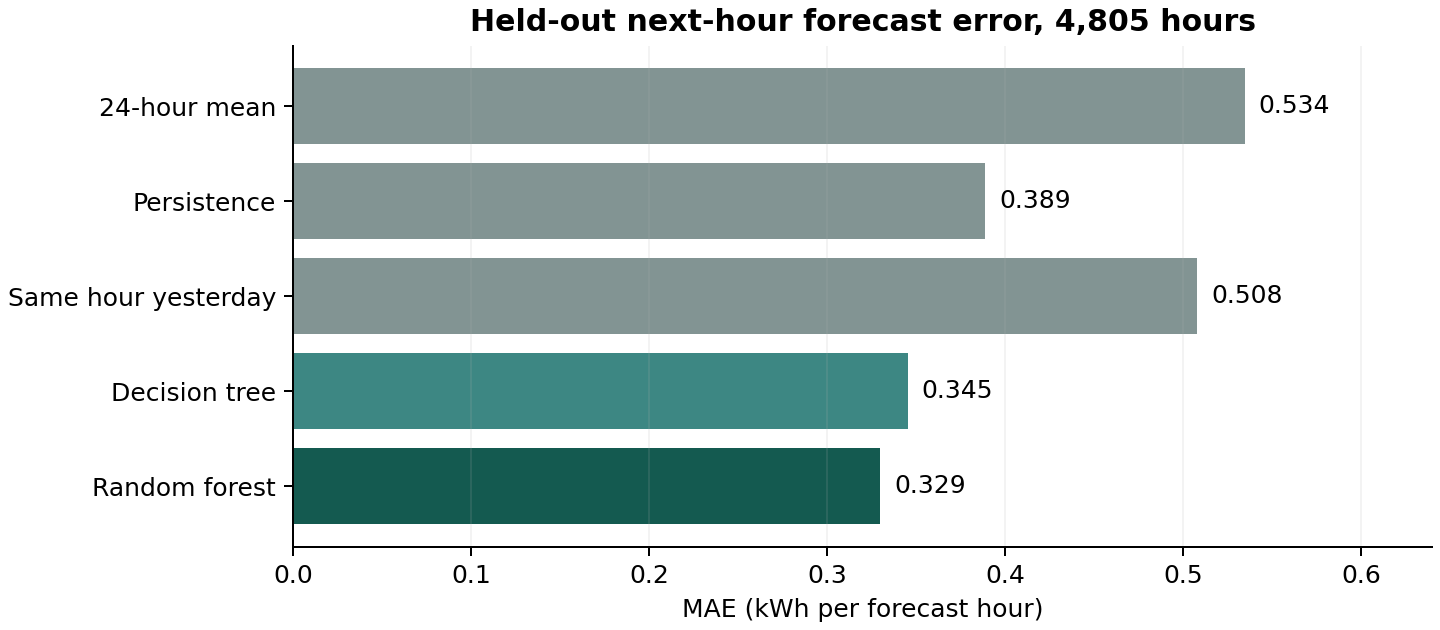

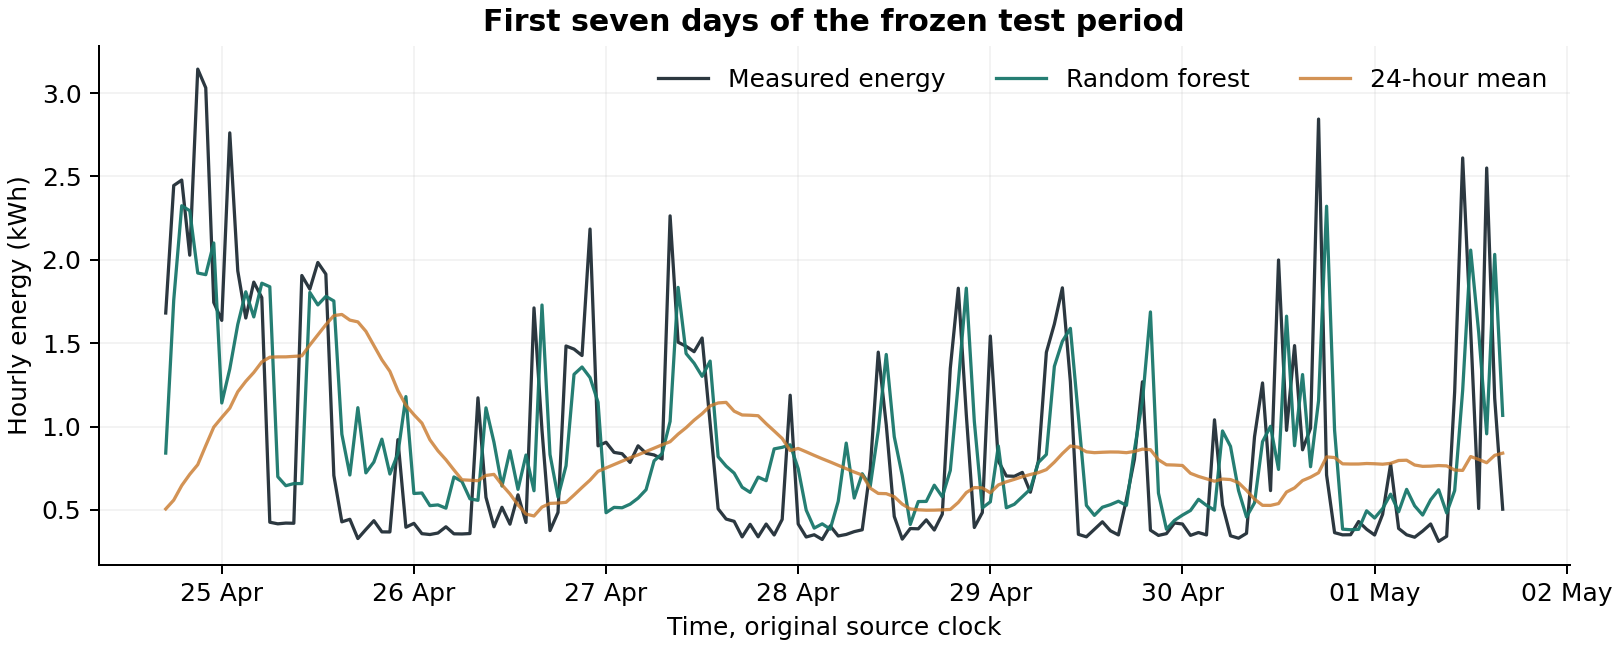

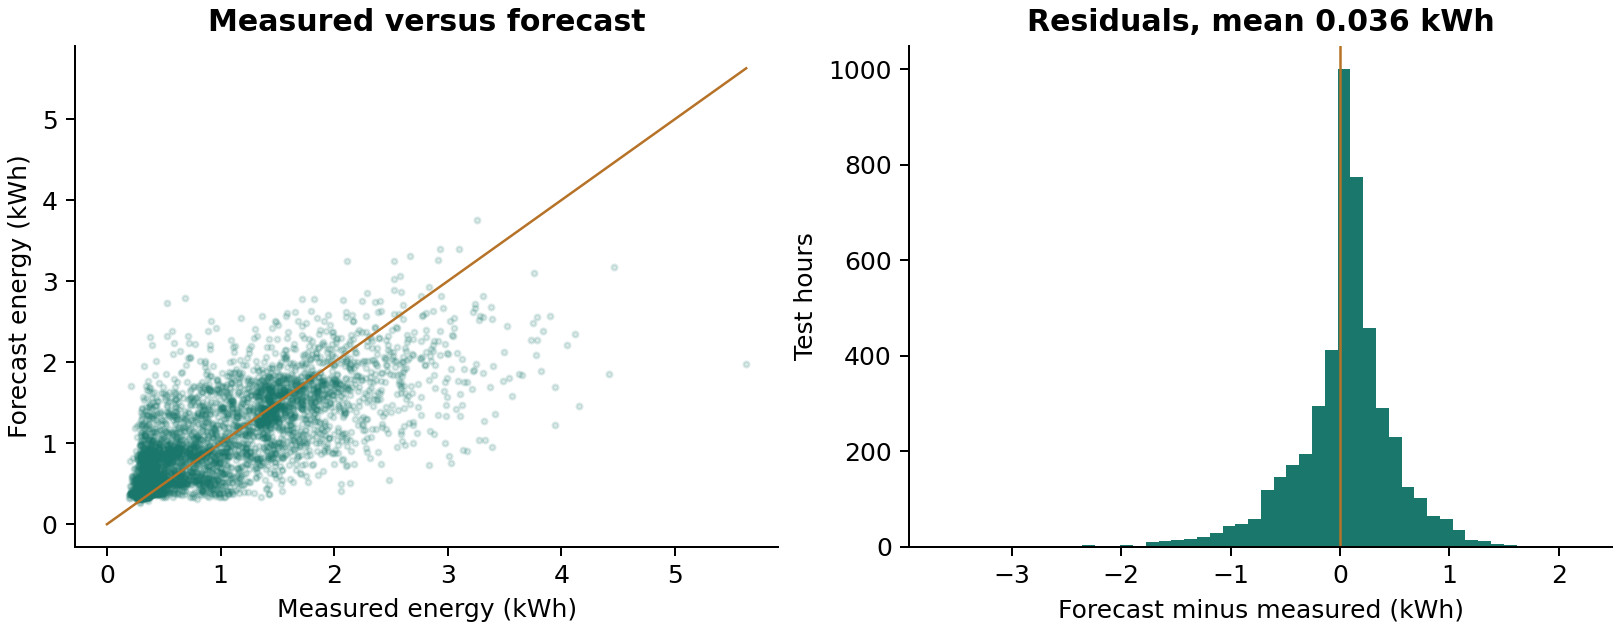

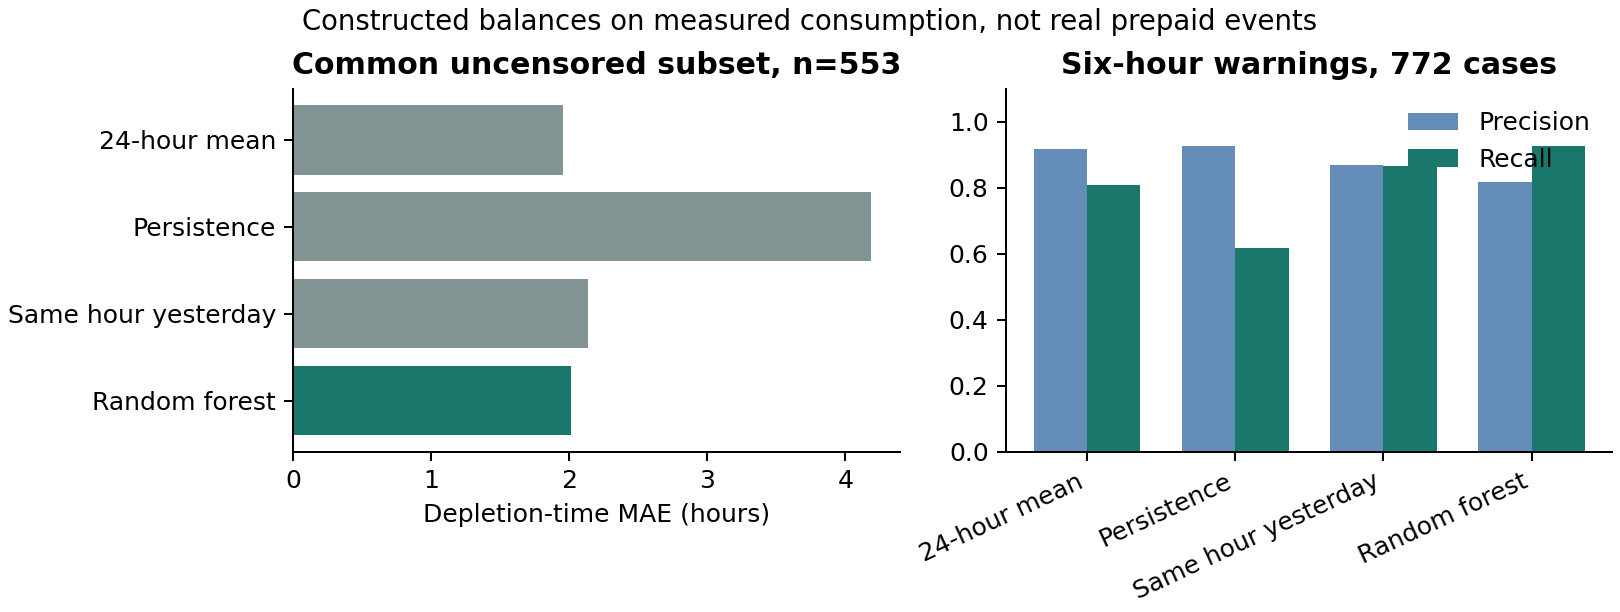

In [5]:
from energy.plots import main as make_plots
make_plots()
# Jupyter displays these saved figures; the standalone executor embeds them too.
try:
    from IPython.display import display, Image
except ImportError:
    print("Figures are saved in figures/ and embedded in this notebook.")
else:
    for filename in ["01_test_mae.png", "02_test_forecast.png", "04_error_diagnostics.png", "05_constructed_scenarios.png"]:
        display(Image(filename=str(Path("figures") / filename)))

## 5. Deployment evidence and limits
Generated C models were compiled on the host and compared with Python for all eligible feature rows. Board compilation, flash/RAM, latency and radio tests are pending. The forest exceeds the aspirational 100 KB array budget; a smaller validation-selected tree is also supplied. Run `python -m energy.export_c` to regenerate these checks with g++.

In [6]:
deployment = json.loads(Path("results/deployment_checks.json").read_text())
print(json.dumps(deployment, indent=2))

{
  "trees": 32,
  "nodes": 13024,
  "constant_array_payload_bytes": 169312,
  "header_source_bytes": 721078,
  "constant_payload_note": "Sum of constant array element sizes. Target-board compiled flash and RAM have not been measured.",
  "compact_tree_alternative": {
    "trees": 1,
    "nodes": 249,
    "constant_array_payload_bytes": 3237,
    "header_source_bytes": 14438,
    "constant_payload_note": "Sum of constant array element sizes. Target-board compiled flash and RAM have not been measured.",
    "host_parity_rows": 32449,
    "max_absolute_prediction_difference_kwh": 1.8062471607294128e-07
  },
  "host_compiler_command": [
    "g++",
    "-std=c++17",
    "-O2",
    "-shared",
    "-fPIC",
    "/workspace/scratch/70396ea95ad0/energy_d2/deployment/host_wrapper.cpp",
    "-o",
    "/workspace/scratch/70396ea95ad0/energy_d2/deployment/host_model.so"
  ],
  "host_parity_rows": 32449,
  "max_absolute_prediction_difference_kwh": 1.7079886927007237e-07,
  "combined_feature_tests": 

## 6. Software API example
This executes the same predictor used by the local HTTP dashboard. The public recorded history is real; the entered 5 kWh balance is assigned. The optional remaining time is conditional on forecasts and no top-ups.

In [7]:
from energy.server import Predictor
predictor = Predictor()
example = predictor.examples()[0]
response = predictor.predict(example)
print(json.dumps({k: response[k] for k in ["forecast_start", "next_hour_kwh", "balance_scenario", "data_mode", "scope"]}, indent=2))

{
  "forecast_start": "2010-04-24T17:00:00",
  "next_hour_kwh": 0.840813902538941,
  "balance_scenario": {
    "starting_balance_kwh": 5.0,
    "balance_source": "manually supplied, not utility verified",
    "assumes_no_topups": true,
    "forecast_horizon_hours": 24,
    "predicted_depletion_hours": 5.4849458257012,
    "warning_within_6h": true,
    "beyond_forecast_horizon": false,
    "within_hour_assumption": "uniform consumption in each forecast hour",
    "baseline_depletion_hours": {
      "mean_24h": 9.884868737723398,
      "persistence": 7.1551230681167715,
      "same_hour_yesterday": 11.312399356067067
    }
  },
  "data_mode": "public_data_replay",
  "scope": "Experimental consumption forecast; not a Yaka balance lookup or validated Ugandan forecast."
}


## 7. Conclusions and next experiments
The selected forest reduces held-out next-hour MAE by 38.36% relative to the 24-hour mean for this source household. This meets the predeclared 10% consumption-error target. The constructed depletion findings are mixed. They do not validate real prepaid warnings or Ugandan applicability.

Next: connect an approved energy sensor and ESP32, measure actual model resources and Wi-Fi behavior, collect consented local energy plus verified balances/top-ups, and evaluate a later untouched local period. Keep the same baseline and report false warnings, missed events, lead time, censoring and sample dependence. See the hardware handoff and full report.